In [98]:
import pandas as pd
import numpy as np
from influxdb_client_3 import InfluxDBClient3, Point

In [107]:
client = InfluxDBClient3(token=f"apiv3_hoBjjFB7ZYYtYy33a_Ui5VTjsWG848623y8Mlf_a_2gVU86YB8gwVjJVYRJXaTUWnS4desa23-y7DcXa4qxmIg", 
                         host=f"http://localhost:8181", database=f"jkp_factors")

query = f"select ret_exc, time from characteristics WHERE gvkey='184996'"

reader = client.query(query=query, language="sql")
df = reader.to_pandas()
stock = df.dropna().sort_values("time")
stock

,ret_exc,time
1,-0.163382,2010-07-31
2,-0.023195,2010-08-31
3,0.047360,2010-09-30
4,0.070214,2010-10-31
5,0.617560,2010-11-30
...,...,...
169,-0.081809,2024-08-31
170,0.217323,2024-09-30
171,-0.048932,2024-10-31
172,0.377514,2024-11-30


In [108]:
def factor_returns(name):
    query = f"select ret, time from factor_returns where name='{name}'"
    return client.query(query=query, language="sql").to_pandas().rename(columns={"ret":f"ret_{name}"})

In [109]:
import statsmodels.api as sm
from functools import reduce

factors = ["value", "momentum", "size"]
factor_data = [factor_returns(factor) for factor in factors]

merged_x = reduce(lambda left, right: pd.merge(left, right, on="time"), factor_data)
merged = pd.merge(merged_x, stock, on="time")

X = sm.add_constant(merged.drop(columns=["ret_exc", "time"]))
y = merged["ret_exc"]

model = sm.OLS(y, X).fit()
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                ret_exc   R-squared:                       0.165
Model:                            OLS   Adj. R-squared:                  0.151
Method:                 Least Squares   F-statistic:                     11.22
Date:                Fri, 06 Jun 2025   Prob (F-statistic):           9.34e-07
Time:                        18:18:07   Log-Likelihood:                 64.333
No. Observations:                 174   AIC:                            -120.7
Df Residuals:                     170   BIC:                            -108.0
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const            0.0548      0.013      4.239      0.000       0.029       0.080
ret_value       -2.1267      0.518     -4.105      0.000      -3.149      -1.104
ret_momentum    -1.6553      0.604     -2.743      0.007      -2.847      -0.464
ret_size         1.2297      0.677      1.815      0.071      -0.108       2.567
==============================================================================
Omnibus:                       49.099   Durbin-Watson:                   1.867
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              116.610
Skew:                           1.220   Prob(JB):                     4.77e-26
Kurtosis:                       6.183   Cond. No.                         62.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

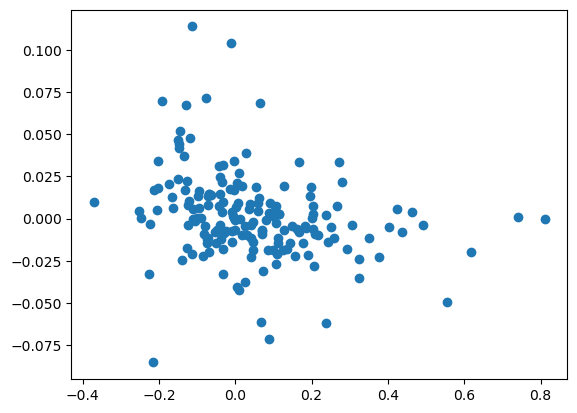

In [111]:
import matplotlib.pyplot as plt

plt.scatter(merged["ret_exc"], merged["ret_value"])